# Area Segmentation Mapping Project - Main Challenge

Land cover mapping is the process of identifying different types of surfaces, such as, trees, buildings, roads, water and agricultural land. This information is useful for urban planning, managing cities/areas and understanding how land is changing.

Analysing multiple aerial views of locations can be quite time consuming and hard, but with machine learning and semantic segmentation, we can automatically classify each pixel of an image into a specific land-cover class. However, different regions have different landscapes, buildings and vegetation, making it harder for a model to generalize to different areas.

The goal of this project is to investigate how accurately CNN models classify different land-covers and how well they perform in unseen data. It is also essential to me to learn a lot about deep learning and computer vision.


## Importing Data

Firstly, I will start by downloading the data, looking into missing values, creating visualizations and make some decisions based on what I find of useful in the data.

In [17]:
import sys
print(sys.executable)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from matplotlib.colors import ListedColormap
from PIL import Image
from pathlib import Path

data_path = Path("../data/OpenEarthMap_wo_xBD")
print("Data path:", data_path)

c:\Users\Francisco\Desktop\Work\Semester 3\Main Challenge\.venv\Scripts\python.exe
Data path: ..\data\OpenEarthMap_wo_xBD


## Initial Data Inspection

In [ ]:
images=list(data_path.glob("*/images/*.tif"))
masks=list(data_path.glob("*/labels/*.tif"))
print("Number of images:", len(images))
print("Number of masks:", len(masks))

Number of images: 3838
Number of masks: 3500


There are some missing masks that I need to look into to understand which ones are missing

In [3]:
image_names={image.name for image in images}
mask_names={mask.name for mask in masks}

missing_masks=image_names-mask_names
missing_images=mask_names-image_names

summary = pd.DataFrame({
    "Status": ["Complete pairs", "Images without masks", "Masks without images"],
    "Count": [
        len(image_names & mask_names),
        len(missing_masks),
        len(missing_images)
    ]
})

display(summary)

,Status,Count
0,Complete pairs,2687
1,Images without masks,1151
2,Masks without images,813


The local dataset contains 2687 pairs (image and mask) and some other records missing that needs to be taken care of afterwards.

## Visual Inspection of Image–Mask Pairs

Understanding image-mask pairs, checking their dimensions and visualizing the images is an important first step to understand the characteristics of the data.

Filename: aachen_1.tif
Region: aachen
Image size: (1000, 1000)
Mask size: (1000, 1000)


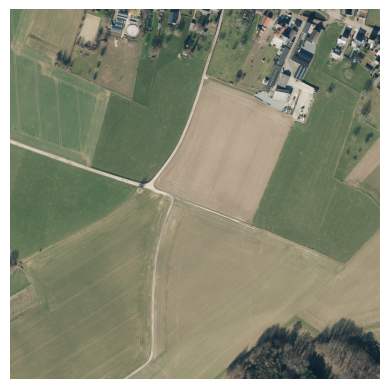

In [8]:
filename=sorted(image_names & mask_names)[0]
region=filename.rsplit("_", 1)[0]

image=Image.open(data_path / region/ "images" /filename)
mask=Image.open(data_path / region / "labels" /filename)

print("Filename:", filename)
print("Region:", region)
print("Image size:", image.size)
print("Mask size:", mask.size)

plt.imshow(image)
plt.axis("off")
plt.show()

The inspected images vary in size. I will need to consider this when preparing the data for training. The main part is seeing if the image and its mask has matching dimensions.

## Image Sizes and Mask Dimensions

In [12]:
sizes=[]

for image_path in images:
    with Image.open(image_path) as image:
        width, height=image.size

    mask_path=image_path.parent.parent / "labels" / image_path.name
    same_size=None
    if mask_path.exists():
        with Image.open(mask_path) as mask:
            same_size=(width, height)==mask.size

    sizes.append({
        "filename": image_path.name,
        "region": image_path.parent.parent.name,
        "width": width,
        "height": height,
        "same_size": same_size
    })

sizes_df=pd.DataFrame(sizes)
display(sizes_df.head())
display(sizes_df.tail())
display(sizes_df[["width", "height"]].describe())

print("Pairs with different dimensions:",
        len(sizes_df[sizes_df["same_size"]==False]))

,filename,region,width,height,same_size
0,aachen_1.tif,aachen,1000,1000,True
1,aachen_10.tif,aachen,1000,1000,True
2,aachen_11.tif,aachen,1000,1000,True
3,aachen_12.tif,aachen,1000,1000,True
4,aachen_13.tif,aachen,1000,1000,True


,filename,region,width,height,same_size
3833,zanzibar_95.tif,zanzibar,1024,1024,True
3834,zanzibar_96.tif,zanzibar,1024,1024,None
3835,zanzibar_97.tif,zanzibar,1024,1024,True
3836,zanzibar_98.tif,zanzibar,1024,1024,True
3837,zanzibar_99.tif,zanzibar,1024,1024,True


,width,height
count,3838.000000,3838.000000
mean,981.912976,981.337415
std,119.449614,122.195872
min,438.000000,406.000000
25%,1000.000000,1000.000000
50%,1024.000000,1024.000000
75%,1024.000000,1024.000000
max,1024.000000,1024.000000


Pairs with different dimensions: 0


This results showcase that the median value of image dimensions is 1024x1024 and this is essential to know that most images will be around this size. This variations need to be considered before training

## Mask Values and Classes
I will be analysing land-cover classes inside masks

In [16]:
classes_df = pd.DataFrame({
    "Label ID": range(9),
    "Class": [
        "Unknown",
        "Bareland",
        "Rangeland",
        "Developed Space",
        "Road",
        "Tree",
        "Water",
        "Agriculture Land",
        "Building"
    ]
})

display(classes_df)

,Label ID,Class
0,0,Unknown
1,1,Bareland
2,2,Rangeland
3,3,Developed Space
4,4,Road
5,5,Tree
6,6,Water
7,7,Agriculture Land
8,8,Building


In [15]:
filename=sorted(image_names & mask_names)[0]
region=filename.rsplit("_", 1)[0]

with Image.open(data_path / region / "labels" / filename) as mask:
    mask_array=np.array(mask)

print("Filename:", filename)
print("Region:", region)
print("Mask shape:", mask_array.shape)
print("Data Type: ", mask_array.dtype)
print("Label IDs:", np.unique(mask_array))

Filename: aachen_1.tif
Region: aachen
Mask shape: (1000, 1000)
Data Type:  uint8
Label IDs: [0 2 3 4 5 6 7 8]


In this image, the class number 1 (bareland) is missing, so this means in certain images, we may not have all classes. Also label 0 means that it is unknown what those pixels mean in our classes.

## Images and Coloured Mask

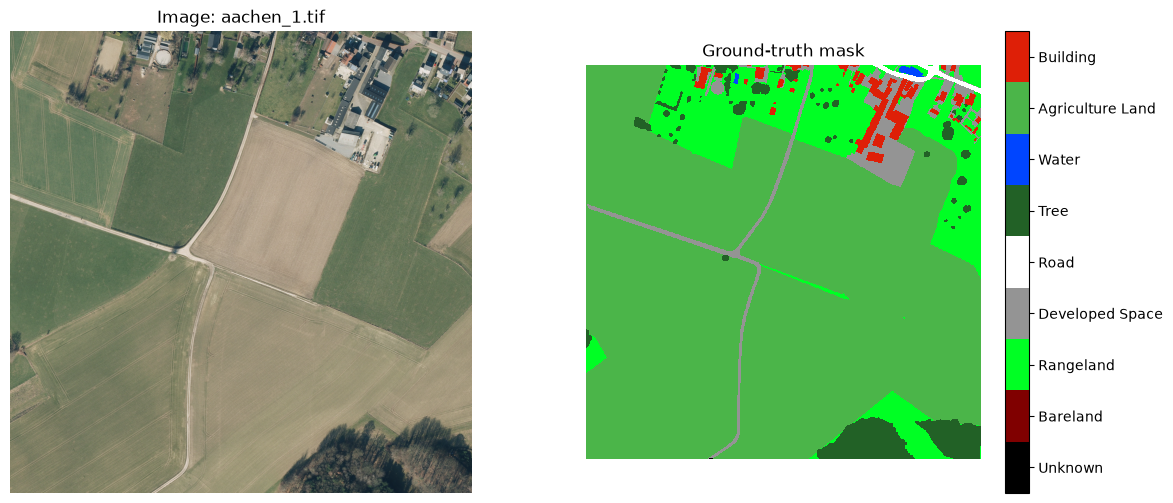

In [18]:
# Official OpenEarthMap colors, ordered by label ID (0–8)
colors = [
    "#000000", "#800000", "#00FF24", "#949494", "#FFFFFF",
    "#226126", "#0045FF", "#4BB549", "#DE1F07"
]
class_colors = ListedColormap(colors)

with Image.open(data_path / region / "images" / filename) as source:
    image_array = np.array(source)

with Image.open(data_path / region / "labels" / filename) as source:
    mask_array=np.array(source)

fig, axes=plt.subplots(1,2, figsize=(14,6))

axes[0].imshow(image_array)
axes[0].set_title(f"Image: {filename}")
axes[0].axis("off")

mask_plot = axes[1].imshow(
    mask_array, cmap=class_colors,
    vmin=-0.5, vmax=8.5, interpolation="nearest"
)
axes[1].set_title("Ground-truth mask")
axes[1].axis("off")

legend = fig.colorbar(mask_plot, ax=axes[1], ticks=range(9))
legend.set_ticklabels(classes_df["Class"])

plt.show()


The inspected image and mask have matching dimensions, and the annotations
appear to be quite consistent with the visible agricultural fields, buildings
and vegetation.

Some road-like paths are labelled as Developed Space rather than Road.
This may reflect annotation criteria or ambiguity between these classes.

These observations concern one sample only. Further examples from different
regions are needed to assess visual consistency across the dataset.

## Observing Consistency across different images

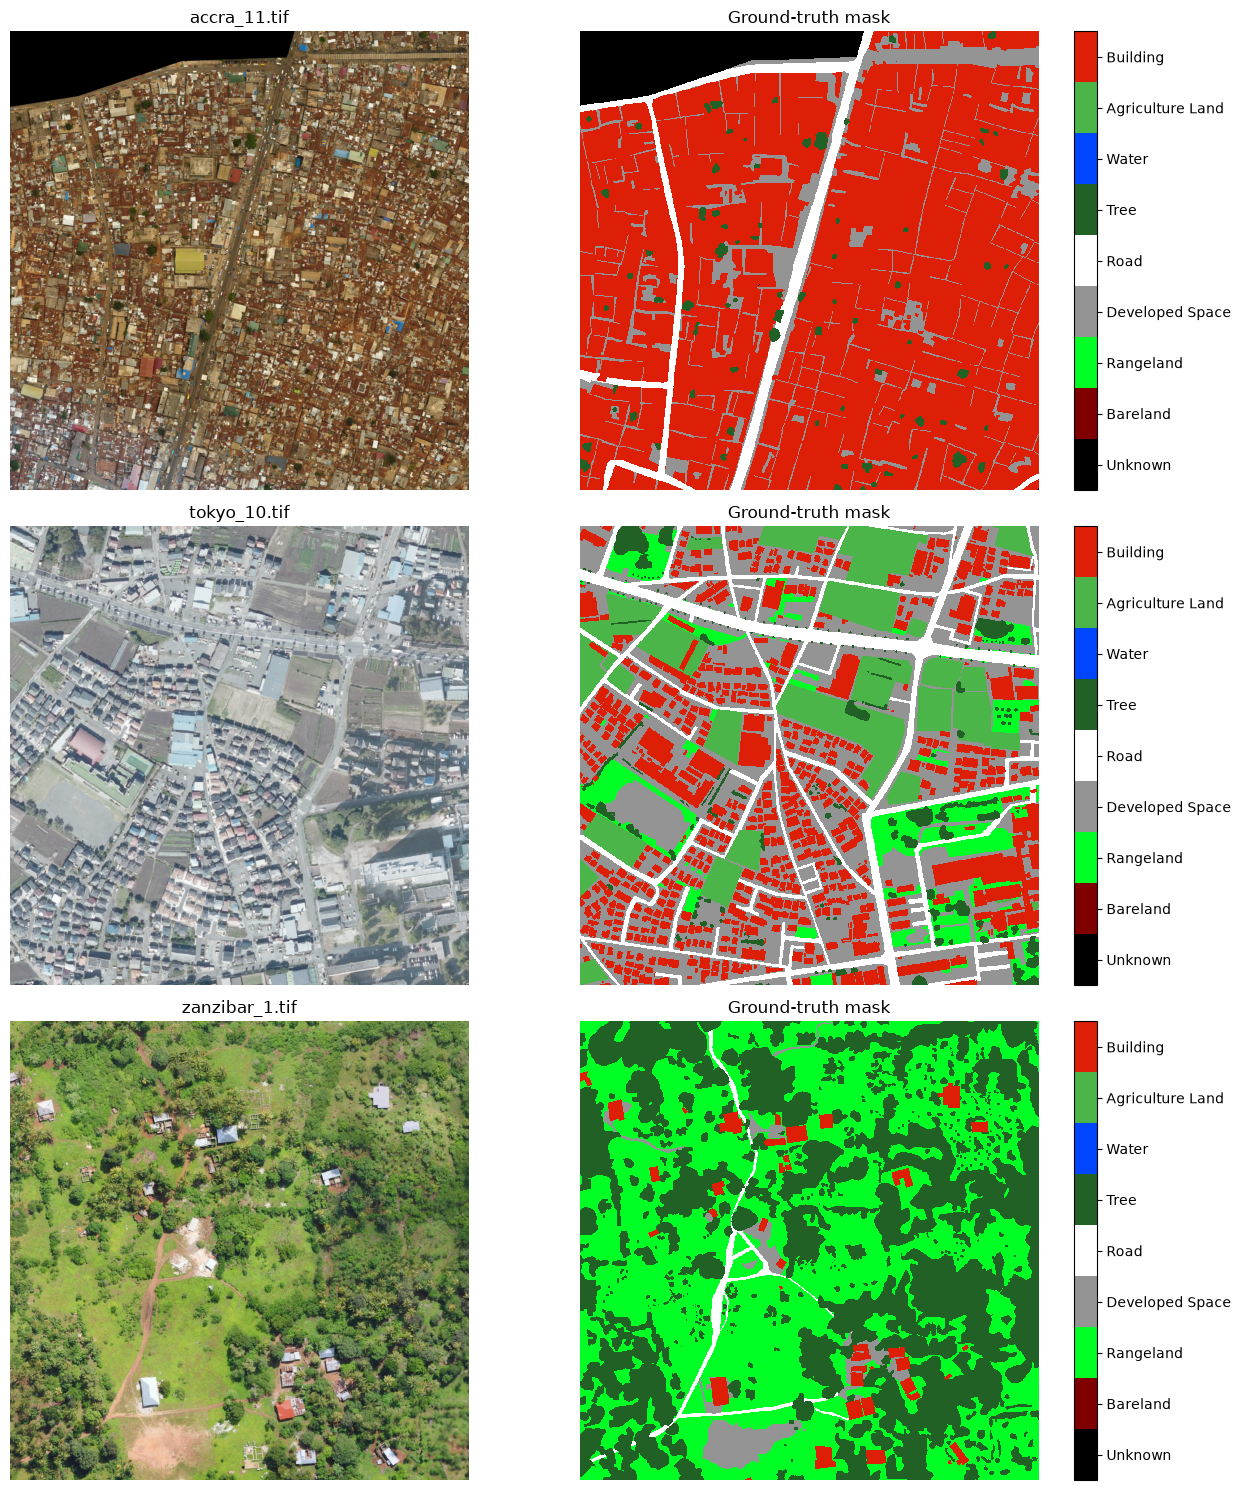

In [20]:
regions = ["accra", "tokyo", "zanzibar"]
paired_names = sorted(image_names & mask_names)

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for row, region in enumerate(regions):
    filename = next(
        name for name in paired_names
        if name.rsplit("_", 1)[0] == region
    )

    for col, folder in enumerate(["images", "labels"]):
        with Image.open(data_path / region / folder / filename) as source:
            pixels = np.array(source)

        axis = axes[row, col]

        if folder == "images":
            axis.imshow(pixels)
        else:
            plot = axis.imshow(
                pixels, cmap=class_colors,
                vmin=-0.5, vmax=8.5, interpolation="nearest"
            )
            legend = fig.colorbar(plot, ax=axis, ticks=range(9))
            legend.set_ticklabels(classes_df["Class"])

        axis.set_title(filename if col == 0 else "Ground-truth mask")
        axis.axis("off")

plt.tight_layout()
plt.show()

As seen above, developed space covers a large number of spaces in the images. It is observed that this class is a bit ambiguous, as it affects for example paths that can be used by cars, bikes or other vehicles and changes them from road to developed place. It only considers road, things that look exactly like a road, especially in length and width.

Another observations is made, especially in Zanzibar, as some places that look like bareground are labeled as Developed Space.

## Class Distribution
Due to the observations seen above, class distribution is important to understand how balanced is our data.

In [24]:
counts = [0] * 9

for path in masks:
    if path.name in image_names:
        with Image.open(path) as mask:
            pixels = np.array(mask)

        for label in range(9):
            counts[label] += (pixels == label).sum()

distribution = classes_df.copy()
distribution = distribution[distribution["Label ID"] != 0].copy()

distribution["Percentage"] = [
    count / sum(counts[1:]) * 100 for count in counts[1:]
]

display(distribution.round(2))

,Label ID,Class,Percentage
1,1,Bareland,1.76
2,2,Rangeland,21.04
3,3,Developed Space,18.88
4,4,Road,6.79
5,5,Tree,18.52
6,6,Water,3.11
7,7,Agriculture Land,12.61
8,8,Building,17.29


The available image-mask pairs show an imbalanced pixel distribution.
Rangeland is the most represented class (21.04%), while Bareland (1.76%) and Water (3.11%) are the least represented.

This imbalance may affect learning of the model.
These percentages exclude unknown pixels and describe pixel frequency, not the number of images containing each class.